In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Locate the project data folder
project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

data_path = project_root / "data" / "processed" / "rossmann_modeling.csv"

# Load the prepared dataset
df = pd.read_csv(data_path, parse_dates=["Date"])

# Sort records chronologically
df = df.sort_values("Date").reset_index(drop=True)

print("BizInsight - Week 9 ML Experiments")
print("----------------------------------")
print("Dataset shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())

display(df.head())


/var/folders/7d/5cs169vx0mxf0_lp0wfnbrdh0000gn/T/ipykernel_53751/3894407689.py:19: DtypeWarning: Columns (7: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_path, parse_dates=["Date"])


BizInsight - Week 9 ML Experiments
----------------------------------
Dataset shape: (844338, 23)
Date range: 2013-01-01 00:00:00 to 2015-07-31 00:00:00


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionDistanceMissing,Year,Month,Day,WeekOfYear
0,85,2,2013-01-01,4220,619,1,0,a,1,b,...,2011.0,0,NaN,NaN,NaN,0,2013,1,1,1
1,1097,2,2013-01-01,5961,1405,1,0,a,1,b,...,2002.0,0,NaN,NaN,NaN,0,2013,1,1,1
2,769,2,2013-01-01,5035,1248,1,0,a,1,b,...,NaN,1,48.0,2012.0,"Jan,Apr,Jul,Oct",0,2013,1,1,1
3,733,2,2013-01-01,10765,2377,1,0,a,1,b,...,1999.0,0,NaN,NaN,NaN,0,2013,1,1,1
4,682,2,2013-01-01,3375,566,1,0,a,1,b,...,2006.0,0,NaN,NaN,NaN,0,2013,1,1,1


In [8]:
# Use the same chronological split as Week 8
train_data = df[df["Date"] < "2015-05-01"].copy()

validation_data = df[
    (df["Date"] >= "2015-05-01") &
    (df["Date"] < "2015-06-01")
].copy()

# Calculate average sales per store and weekday
baseline = (
    train_data
    .groupby(["Store", "DayOfWeek"])["Sales"]
    .mean()
)

# Generate predictions for validation data
baseline_predictions = pd.Series(
    validation_data.set_index(
        ["Store", "DayOfWeek"]
    ).index.map(baseline),
    index=validation_data.index
)

# Fallback for combinations not seen in training
baseline_predictions = baseline_predictions.fillna(
    train_data["Sales"].mean()
)

# Calculate evaluation metrics
baseline_mae = mean_absolute_error(
    validation_data["Sales"],
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        validation_data["Sales"],
        baseline_predictions
    )
)

print("Baseline Model - Validation Evaluation")
print("--------------------------------------")
print(f"MAE: {baseline_mae:.2f}")
print(f"RMSE: {baseline_rmse:.2f}")

# Display sample predictions
baseline_results = validation_data[
    ["Date", "Store", "Sales"]
].copy()

baseline_results["PredictedSales"] = (
    baseline_predictions.round(2)
)

display(baseline_results.head(10))


Baseline Model - Validation Evaluation
--------------------------------------
MAE: 1016.53
RMSE: 1359.94


,Date,Store,Sales,PredictedSales
759848,2015-05-01,512,10534,6049.68
759849,2015-05-01,562,22866,18742.40
759850,2015-05-01,676,16555,7574.19
759851,2015-05-01,682,8406,12135.36
759852,2015-05-01,948,13571,7082.78
759853,2015-05-01,769,15302,11769.29
759854,2015-05-01,1097,17039,9892.74
759855,2015-05-01,1081,4374,6245.34
759856,2015-05-01,733,19899,15950.83
759857,2015-05-01,494,8347,7832.17


In [9]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Week 9 - Step 3: Decision Tree Model

# Select features
features = [
    "Store", "DayOfWeek", "Month", "Day",
    "Promo", "SchoolHoliday", "StoreType"
]

# Prepare training and validation features
X_train = pd.get_dummies(
    train_data[features],
    columns=["StoreType"],
    dtype=int
)

X_val = pd.get_dummies(
    validation_data[features],
    columns=["StoreType"],
    dtype=int
)

# Ensure identical feature columns
X_val = X_val.reindex(
    columns=X_train.columns,
    fill_value=0
)

y_train = train_data["Sales"]
y_val = validation_data["Sales"]

# Create and train the model
decision_tree = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=10,
    random_state=42
)

decision_tree.fit(X_train, y_train)

# Predict validation sales
tree_predictions = decision_tree.predict(X_val)

# Evaluate model
tree_mae = mean_absolute_error(
    y_val, tree_predictions
)

tree_rmse = np.sqrt(
    mean_squared_error(y_val, tree_predictions)
)

print("Decision Tree - Validation Evaluation")
print("-------------------------------------")
print(f"MAE: {tree_mae:.2f}")
print(f"RMSE: {tree_rmse:.2f}")

# Compare with baseline
print("\nBaseline vs Decision Tree")
print(f"Baseline MAE: {baseline_mae:.2f}")
print(f"Decision Tree MAE: {tree_mae:.2f}")
print(f"Baseline RMSE: {baseline_rmse:.2f}")
print(f"Decision Tree RMSE: {tree_rmse:.2f}")

Decision Tree - Validation Evaluation
-------------------------------------
MAE: 1982.81
RMSE: 2747.39

Baseline vs Decision Tree
Baseline MAE: 1016.53
Decision Tree MAE: 1982.81
Baseline RMSE: 1359.94
Decision Tree RMSE: 2747.39


In [10]:
from sklearn.ensemble import RandomForestRegressor

# Week 9 - Step 4: Random Forest Model

# Create Random Forest model
random_forest = RandomForestRegressor(
    n_estimators=50,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train the model
random_forest.fit(X_train, y_train)

# Predict validation sales
rf_predictions = random_forest.predict(X_val)

# Evaluate predictions
rf_mae = mean_absolute_error(
    y_val, rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(y_val, rf_predictions)
)

print("Random Forest - Validation Evaluation")
print("-------------------------------------")
print(f"MAE: {rf_mae:.2f}")
print(f"RMSE: {rf_rmse:.2f}")

# Compare all three models
comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        tree_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        tree_rmse,
        rf_rmse
    ]
})

comparison = comparison.sort_values("MAE")

print("\nModel Comparison:")
display(comparison.round(2))


Random Forest - Validation Evaluation
-------------------------------------
MAE: 1875.29
RMSE: 2594.89

Model Comparison:


,Model,MAE,RMSE
0,Baseline,1016.53,1359.94
2,Random Forest,1875.29,2594.89
1,Decision Tree,1982.81,2747.39


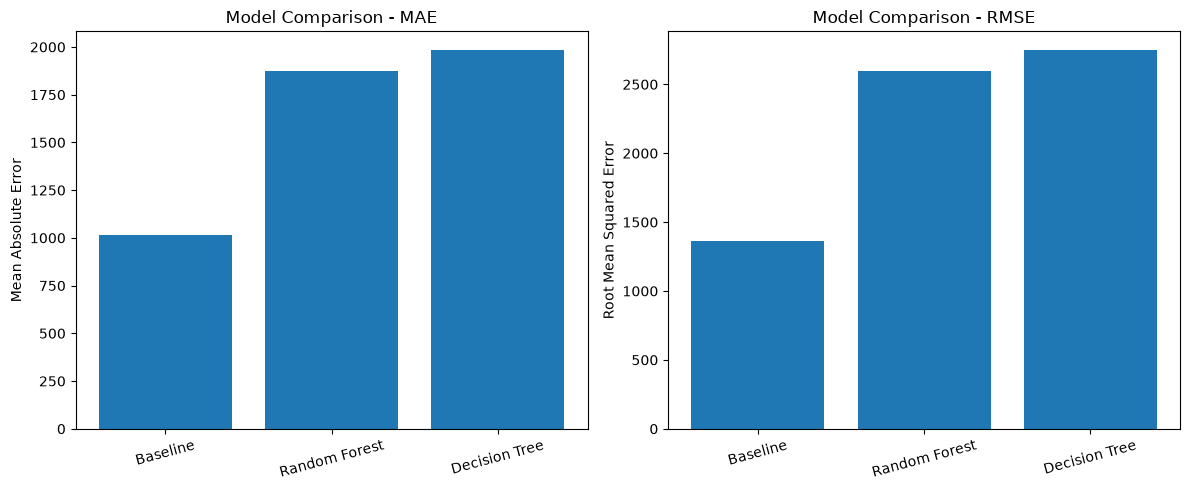

Best Model Based on Validation MAE
----------------------------------
Model: Baseline
MAE: 1016.53
RMSE: 1359.94


In [11]:
import matplotlib.pyplot as plt

# Week 9 - Step 5: Model Comparison

# Sort models by MAE
comparison = comparison.sort_values("MAE")

# Create two charts
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# MAE comparison
axes[0].bar(
    comparison["Model"],
    comparison["MAE"]
)
axes[0].set_title("Model Comparison - MAE")
axes[0].set_ylabel("Mean Absolute Error")
axes[0].tick_params(axis="x", rotation=15)

# RMSE comparison
axes[1].bar(
    comparison["Model"],
    comparison["RMSE"]
)
axes[1].set_title("Model Comparison - RMSE")
axes[1].set_ylabel("Root Mean Squared Error")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

# Identify best-performing model
best_model = comparison.iloc[0]

print("Best Model Based on Validation MAE")
print("----------------------------------")
print("Model:", best_model["Model"])
print(f"MAE: {best_model['MAE']:.2f}")
print(f"RMSE: {best_model['RMSE']:.2f}")


In [12]:
from pathlib import Path

# Create results directory
results_dir = project_root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

# Save model comparison
comparison.to_csv(
    results_dir / "week9_model_comparison.csv",
    index=False
)

# Identify best model
best_model = comparison.iloc[0]

# Calculate Random Forest improvement over Decision Tree
improvement = (
    (tree_mae - rf_mae) / tree_mae
) * 100

print("BizInsight - Week 9 Final Summary")
print("---------------------------------")
print("Models evaluated: 3")
print("Evaluation period: May 2015")
print("Evaluation metrics: MAE and RMSE")

print("\nBest-performing model:")
print(f"Model: {best_model['Model']}")
print(f"MAE: {best_model['MAE']:.2f}")
print(f"RMSE: {best_model['RMSE']:.2f}")

print("\nMachine Learning Results:")
print(f"Decision Tree MAE: {tree_mae:.2f}")
print(f"Random Forest MAE: {rf_mae:.2f}")
print(
    f"Random Forest improves on Decision Tree "
    f"by {improvement:.2f}% in MAE."
)

print("\nConclusion:")
print(
    "The baseline achieved the lowest validation error. "
    "Random Forest outperformed Decision Tree, but neither "
    "ML model surpassed the baseline. Further feature "
    "engineering and model tuning may improve performance."
)

print("\nResults saved to:")
print(results_dir / "week9_model_comparison.csv")


BizInsight - Week 9 Final Summary
---------------------------------
Models evaluated: 3
Evaluation period: May 2015
Evaluation metrics: MAE and RMSE

Best-performing model:
Model: Baseline
MAE: 1016.53
RMSE: 1359.94

Machine Learning Results:
Decision Tree MAE: 1982.81
Random Forest MAE: 1875.29
Random Forest improves on Decision Tree by 5.42% in MAE.

Conclusion:
The baseline achieved the lowest validation error. Random Forest outperformed Decision Tree, but neither ML model surpassed the baseline. Further feature engineering and model tuning may improve performance.

Results saved to:
/Users/martinagj/Desktop/BizInsight/bizinsight/results/week9_model_comparison.csv


In [13]:
# Week 11 - Step 1: Analyze Prediction Errors

error_analysis = validation_data[
    ["Store", "Date", "Promo", "Sales"]
].copy()

# Add predictions
error_analysis["Baseline"] = baseline_predictions.values
error_analysis["DecisionTree"] = tree_predictions
error_analysis["RandomForest"] = rf_predictions

# Calculate absolute errors
for model in ["Baseline", "DecisionTree", "RandomForest"]:
    error_analysis[f"{model}_Error"] = abs(
        error_analysis["Sales"] - error_analysis[model]
    )

# Compare average errors by promotion status
promo_errors = error_analysis.groupby("Promo")[
    ["Baseline_Error", "DecisionTree_Error", "RandomForest_Error"]
].mean()

print("Average Prediction Errors by Promotion Status")
display(promo_errors.round(2))

Average Prediction Errors by Promotion Status


,Baseline_Error,DecisionTree_Error,RandomForest_Error
Promo,,,
0,980.38,2012.23,1904.16
1,1064.18,1944.02,1837.22


In [14]:
# Week 11 - Step 2: Historical Sales Features

# Create copies to keep the original datasets unchanged
train_improved = train_data.copy()
validation_improved = validation_data.copy()

# Calculate averages using training data only
store_avg = train_data.groupby("Store")["Sales"].mean()

store_weekday_avg = train_data.groupby(
    ["Store", "DayOfWeek"]
)["Sales"].mean()

global_avg = train_data["Sales"].mean()

# Add historical features to both datasets
for dataset in [train_improved, validation_improved]:

    dataset["StoreAvgSales"] = (
        dataset["Store"].map(store_avg).fillna(global_avg)
    )

    dataset["StoreWeekdayAvgSales"] = (
        pd.Series(
            dataset.set_index(["Store", "DayOfWeek"]).index.map(
                store_weekday_avg
            ),
            index=dataset.index
        ).fillna(dataset["StoreAvgSales"])
    )

# Check the new features
print("Training dataset:")
display(train_improved[
    ["Store", "DayOfWeek", "Sales",
     "StoreAvgSales", "StoreWeekdayAvgSales"]
].head())

print("Validation dataset:")
display(validation_improved[
    ["Store", "DayOfWeek", "Sales",
     "StoreAvgSales", "StoreWeekdayAvgSales"]
].head())

print("Missing values in new features:")
print(validation_improved[
    ["StoreAvgSales", "StoreWeekdayAvgSales"]
].isna().sum())

Training dataset:


,Store,DayOfWeek,Sales,StoreAvgSales,StoreWeekdayAvgSales
0,85,2,4220,7243.131765,6528.983607
1,1097,2,5961,9609.298824,9367.122951
2,769,2,5035,10649.698824,10063.885246
3,733,2,10765,14898.872941,14532.270492
4,682,2,3375,11192.556471,12806.721311


Validation dataset:


,Store,DayOfWeek,Sales,StoreAvgSales,StoreWeekdayAvgSales
759848,512,5,10534,5353.597243,6049.677419
759849,562,5,22866,17982.478824,18742.404959
759850,676,5,16555,7455.186441,7574.194915
759851,682,5,8406,11192.556471,12135.355372
759852,948,5,13571,6770.161677,7082.781513


Missing values in new features:
StoreAvgSales           0
StoreWeekdayAvgSales    0
dtype: int64


In [15]:
# Week 11 - Step 3: Improved Decision Tree

# Original features + historical sales features
improved_features = [
    "Store", "DayOfWeek", "Month", "Day",
    "Promo", "SchoolHoliday", "StoreType",
    "StoreAvgSales", "StoreWeekdayAvgSales"
]

# Prepare training and validation inputs
X_train_improved = pd.get_dummies(
    train_improved[improved_features],
    columns=["StoreType"],
    dtype=int
)

X_val_improved = pd.get_dummies(
    validation_improved[improved_features],
    columns=["StoreType"],
    dtype=int
)

# Ensure both datasets have identical columns
X_val_improved = X_val_improved.reindex(
    columns=X_train_improved.columns,
    fill_value=0
)

# Train improved Decision Tree
improved_tree = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=5,
    random_state=42
)

improved_tree.fit(X_train_improved, y_train)

# Generate predictions
improved_tree_predictions = improved_tree.predict(
    X_val_improved
)

# Evaluate predictions
improved_tree_mae = mean_absolute_error(
    y_val, improved_tree_predictions
)

improved_tree_rmse = np.sqrt(
    mean_squared_error(y_val, improved_tree_predictions)
)

# Compare old and new results
print("Decision Tree Comparison")
print("------------------------")
print(f"Original MAE: {tree_mae:.2f}")
print(f"Improved MAE: {improved_tree_mae:.2f}")
print()
print(f"Original RMSE: {tree_rmse:.2f}")
print(f"Improved RMSE: {improved_tree_rmse:.2f}")
print()
print(f"Baseline MAE: {baseline_mae:.2f}")

Decision Tree Comparison
------------------------
Original MAE: 1982.81
Improved MAE: 906.73

Original RMSE: 2747.39
Improved RMSE: 1263.03

Baseline MAE: 1016.53


In [16]:
# Week 11 - Step 4: Time-Safe Historical Features

# Sort training records by date
train_safe = train_data.sort_values(
    ["Date", "Store"]
).copy()

validation_safe = validation_data.copy()

# Calculate historical averages using only earlier dates
store_daily = (
    train_safe.groupby(["Store", "Date"])["Sales"]
    .mean()
    .reset_index()
    .sort_values(["Store", "Date"])
)

store_daily["PastStoreAvg"] = (
    store_daily.groupby("Store")["Sales"]
    .transform(lambda s: s.shift(1).expanding().mean())
)

# Merge past store averages into training data
train_safe = train_safe.merge(
    store_daily[["Store", "Date", "PastStoreAvg"]],
    on=["Store", "Date"],
    how="left",
    validate="many_to_one"
)

# For validation, use averages from training only
store_avg = train_data.groupby("Store")["Sales"].mean()
global_avg = train_data["Sales"].mean()

validation_safe["PastStoreAvg"] = (
    validation_safe["Store"]
    .map(store_avg)
    .fillna(global_avg)
)

# Check results
print("Training historical averages:")
display(train_safe[
    ["Date", "Store", "Sales", "PastStoreAvg"]
].head(10))

print("Validation historical averages:")
display(validation_safe[
    ["Date", "Store", "Sales", "PastStoreAvg"]
].head(10))

print("Missing training values:",
      train_safe["PastStoreAvg"].isna().sum())

Training historical averages:


,Date,Store,Sales,PastStoreAvg
0,2013-01-01,85,4220,NaN
1,2013-01-01,259,6851,NaN
2,2013-01-01,262,17267,NaN
3,2013-01-01,274,3102,NaN
4,2013-01-01,335,2401,NaN
5,2013-01-01,353,3139,NaN
6,2013-01-01,423,9643,NaN
7,2013-01-01,494,3113,NaN
8,2013-01-01,512,2646,NaN
9,2013-01-01,530,2907,NaN


Validation historical averages:


,Date,Store,Sales,PastStoreAvg
759848,2015-05-01,512,10534,5353.597243
759849,2015-05-01,562,22866,17982.478824
759850,2015-05-01,676,16555,7455.186441
759851,2015-05-01,682,8406,11192.556471
759852,2015-05-01,948,13571,6770.161677
759853,2015-05-01,769,15302,10649.698824
759854,2015-05-01,1097,17039,9609.298824
759855,2015-05-01,1081,4374,5863.078195
759856,2015-05-01,733,19899,14898.872941
759857,2015-05-01,494,8347,7635.155294


Missing training values: 1115


In [17]:
# Week 11 - Step 5: Time-Safe Store and Weekday Averages

# Calculate previous sales averages for each store and weekday
train_safe["PastStoreWeekdayAvg"] = (
    train_safe.groupby(["Store", "DayOfWeek"])["Sales"]
    .transform(lambda s: s.shift(1).expanding().mean())
)

# Calculate store-weekday averages from training data only
weekday_avg = train_data.groupby(
    ["Store", "DayOfWeek"]
)["Sales"].mean()

# Add historical weekday averages to validation data
validation_safe["PastStoreWeekdayAvg"] = (
    pd.Series(
        validation_safe.set_index(
            ["Store", "DayOfWeek"]
        ).index.map(weekday_avg),
        index=validation_safe.index
    )
)

# Handle missing values without using future sales
# Keep early training records missing for now;
# we'll handle them before model training.

print("Training historical features:")
display(train_safe[
    ["Date", "Store", "DayOfWeek", "Sales",
     "PastStoreAvg", "PastStoreWeekdayAvg"]
].head(10))

print("Validation historical features:")
display(validation_safe[
    ["Date", "Store", "DayOfWeek", "Sales",
     "PastStoreAvg", "PastStoreWeekdayAvg"]
].head(10))

print("Missing training values:")
print(train_safe[
    ["PastStoreAvg", "PastStoreWeekdayAvg"]
].isna().sum())

print("Missing validation values:")
print(validation_safe[
    ["PastStoreAvg", "PastStoreWeekdayAvg"]
].isna().sum())

Training historical features:


,Date,Store,DayOfWeek,Sales,PastStoreAvg,PastStoreWeekdayAvg
0,2013-01-01,85,2,4220,NaN,NaN
1,2013-01-01,259,2,6851,NaN,NaN
2,2013-01-01,262,2,17267,NaN,NaN
3,2013-01-01,274,2,3102,NaN,NaN
4,2013-01-01,335,2,2401,NaN,NaN
5,2013-01-01,353,2,3139,NaN,NaN
6,2013-01-01,423,2,9643,NaN,NaN
7,2013-01-01,494,2,3113,NaN,NaN
8,2013-01-01,512,2,2646,NaN,NaN
9,2013-01-01,530,2,2907,NaN,NaN


Validation historical features:


,Date,Store,DayOfWeek,Sales,PastStoreAvg,PastStoreWeekdayAvg
759848,2015-05-01,512,5,10534,5353.597243,6049.677419
759849,2015-05-01,562,5,22866,17982.478824,18742.404959
759850,2015-05-01,676,5,16555,7455.186441,7574.194915
759851,2015-05-01,682,5,8406,11192.556471,12135.355372
759852,2015-05-01,948,5,13571,6770.161677,7082.781513
759853,2015-05-01,769,5,15302,10649.698824,11769.289256
759854,2015-05-01,1097,5,17039,9609.298824,9892.735537
759855,2015-05-01,1081,5,4374,5863.078195,6245.336842
759856,2015-05-01,733,5,19899,14898.872941,15950.826446
759857,2015-05-01,494,5,8347,7635.155294,7832.173554


Missing training values:
PastStoreAvg           1115
PastStoreWeekdayAvg    6723
dtype: int64
Missing validation values:
PastStoreAvg           0
PastStoreWeekdayAvg    0
dtype: int64


In [18]:
# Week 11 - Step 6: Prepare Time-Safe Training Data

# Remove early records without historical information
train_final = train_safe.dropna(
    subset=["PastStoreAvg", "PastStoreWeekdayAvg"]
).copy()

validation_final = validation_safe.copy()

# Select original and historical features
final_features = [
    "Store", "DayOfWeek", "Month", "Day",
    "Promo", "SchoolHoliday", "StoreType",
    "PastStoreAvg", "PastStoreWeekdayAvg"
]

# Prepare numerical features
X_train_final = pd.get_dummies(
    train_final[final_features],
    columns=["StoreType"],
    dtype=int
)

X_val_final = pd.get_dummies(
    validation_final[final_features],
    columns=["StoreType"],
    dtype=int
)

# Match validation columns to training columns
X_val_final = X_val_final.reindex(
    columns=X_train_final.columns,
    fill_value=0
)

# Prepare actual sales values
y_train_final = train_final["Sales"]
y_val_final = validation_final["Sales"]

# Verification
print("Training records:", len(X_train_final))
print("Validation records:", len(X_val_final))

print("Missing training values:",
      X_train_final.isna().sum().sum())

print("Missing validation values:",
      X_val_final.isna().sum().sum())

print("Number of features:", X_train_final.shape[1])

Training records: 753125
Validation records: 25879
Missing training values: 0
Missing validation values: 0
Number of features: 12


In [19]:
# Week 11 - Step 7: Retrain Decision Tree

# Create Decision Tree with time-safe features
safe_tree = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=5,
    random_state=42
)

# Train the model
safe_tree.fit(X_train_final, y_train_final)

# Predict validation sales
safe_tree_predictions = safe_tree.predict(X_val_final)

# Calculate prediction errors
safe_tree_mae = mean_absolute_error(
    y_val_final, safe_tree_predictions
)

safe_tree_rmse = np.sqrt(
    mean_squared_error(y_val_final, safe_tree_predictions)
)

# Compare results
print("Decision Tree - Final Comparison")
print("--------------------------------")

print(f"Original Decision Tree MAE: {tree_mae:.2f}")
print(f"Time-Safe Decision Tree MAE: {safe_tree_mae:.2f}")
print(f"Baseline MAE: {baseline_mae:.2f}")

print()

print(f"Original Decision Tree RMSE: {tree_rmse:.2f}")
print(f"Time-Safe Decision Tree RMSE: {safe_tree_rmse:.2f}")
print(f"Baseline RMSE: {baseline_rmse:.2f}")

# Calculate improvement
improvement = (
    (tree_mae - safe_tree_mae) / tree_mae
) * 100

print()
print(f"MAE Improvement: {improvement:.2f}%")


Decision Tree - Final Comparison
--------------------------------
Original Decision Tree MAE: 1982.81
Time-Safe Decision Tree MAE: 852.76
Baseline MAE: 1016.53

Original Decision Tree RMSE: 2747.39
Time-Safe Decision Tree RMSE: 1199.80
Baseline RMSE: 1359.94

MAE Improvement: 56.99%


In [20]:
# Week 11 - Step 8: Improved Random Forest

# Create Random Forest with time-safe features
safe_forest = RandomForestRegressor(
    n_estimators=50,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train the model
safe_forest.fit(X_train_final, y_train_final)

# Predict validation sales
safe_forest_predictions = safe_forest.predict(X_val_final)

# Calculate prediction errors
safe_forest_mae = mean_absolute_error(
    y_val_final, safe_forest_predictions
)

safe_forest_rmse = np.sqrt(
    mean_squared_error(y_val_final, safe_forest_predictions)
)

# Compare results
print("Random Forest - Comparison")
print("--------------------------")

print(f"Original Random Forest MAE: {rf_mae:.2f}")
print(f"Improved Random Forest MAE: {safe_forest_mae:.2f}")
print(f"Baseline MAE: {baseline_mae:.2f}")

print()

print(f"Original Random Forest RMSE: {rf_rmse:.2f}")
print(f"Improved Random Forest RMSE: {safe_forest_rmse:.2f}")
print(f"Baseline RMSE: {baseline_rmse:.2f}")

# Calculate improvement
rf_improvement = (
    (rf_mae - safe_forest_mae) / rf_mae
) * 100

print()
print(f"MAE Improvement: {rf_improvement:.2f}%")

Random Forest - Comparison
--------------------------
Original Random Forest MAE: 1875.29
Improved Random Forest MAE: 794.71
Baseline MAE: 1016.53

Original Random Forest RMSE: 2594.89
Improved Random Forest RMSE: 1120.68
Baseline RMSE: 1359.94

MAE Improvement: 57.62%


Random Forest - Feature Importance


,Feature,Importance
7,PastStoreWeekdayAvg,0.7342
4,Promo,0.1228
3,Day,0.0401
2,Month,0.0388
6,PastStoreAvg,0.0291
1,DayOfWeek,0.0248
0,Store,0.0043
5,SchoolHoliday,0.0025
8,StoreType_a,0.0009
9,StoreType_b,0.0009


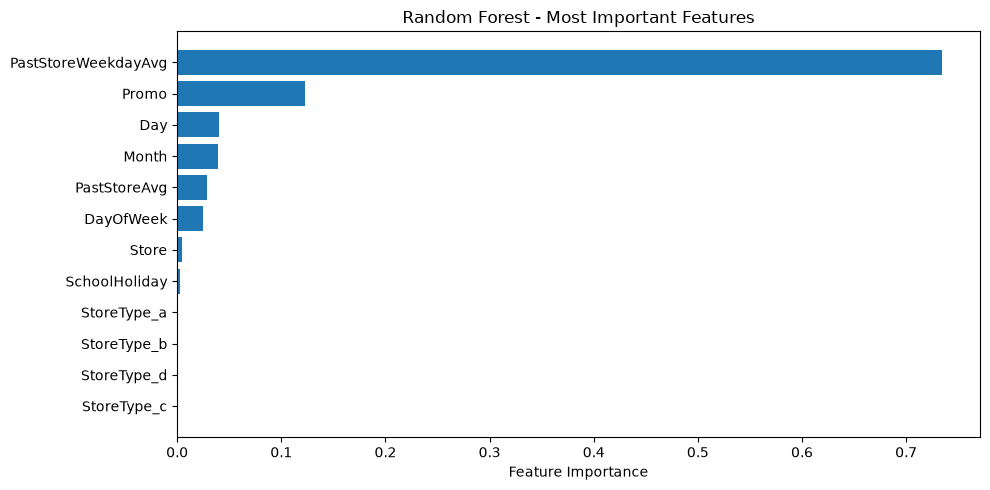

In [21]:
# Week 11 - Step 9: Random Forest Feature Importance

importance = pd.DataFrame({
    "Feature": X_train_final.columns,
    "Importance": safe_forest.feature_importances_
})

importance = importance.sort_values(
    "Importance", ascending=False
)

print("Random Forest - Feature Importance")
display(importance.round(4))

# Visualize the results
plt.figure(figsize=(10, 5))
plt.barh(
    importance["Feature"],
    importance["Importance"]
)
plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.title("Random Forest - Most Important Features")
plt.tight_layout()
plt.show()

In [22]:
# Week 11 - Step 10: Prepare Final Test Dataset

# Select the untouched test period
test_final = df[
    df["Date"] >= "2015-06-01"
].copy()

# Use only historical data before the test period
history = df[
    df["Date"] < "2015-06-01"
].copy()

# Calculate historical store averages
store_avg_test = history.groupby("Store")["Sales"].mean()

# Calculate historical store-weekday averages
weekday_avg_test = history.groupby(
    ["Store", "DayOfWeek"]
)["Sales"].mean()

# Add historical features to test data
test_final["PastStoreAvg"] = (
    test_final["Store"].map(store_avg_test)
)

test_final["PastStoreWeekdayAvg"] = pd.Series(
    test_final.set_index(
        ["Store", "DayOfWeek"]
    ).index.map(weekday_avg_test),
    index=test_final.index
)

# Prepare test features
X_test_final = pd.get_dummies(
    test_final[final_features],
    columns=["StoreType"],
    dtype=int
)

# Match training features
X_test_final = X_test_final.reindex(
    columns=X_train_final.columns,
    fill_value=0
)

y_test_final = test_final["Sales"]

# Verify dataset
print("Test records:", len(X_test_final))
print("Number of features:", X_test_final.shape[1])
print("Missing values:", X_test_final.isna().sum().sum())

print("Test period:",
      test_final["Date"].min(),
      "to",
      test_final["Date"].max())

display(X_test_final.head())

Test records: 58611
Number of features: 12
Missing values: 0
Test period: 2015-06-01 00:00:00 to 2015-07-31 00:00:00


,Store,DayOfWeek,Month,Day,Promo,SchoolHoliday,PastStoreAvg,PastStoreWeekdayAvg,StoreType_a,StoreType_b,StoreType_c,StoreType_d
785727,747,1,6,1,1,0,8023.823934,9365.067797,0,0,1,0
785728,746,1,6,1,1,0,5977.026063,7028.403361,0,0,0,1
785729,745,1,6,1,1,0,7492.046768,10234.033613,1,0,0,0
785730,744,1,6,1,1,1,7421.990958,8286.000000,1,0,0,0
785731,743,1,6,1,1,0,3808.477304,5055.378151,1,0,0,0


In [23]:
# Week 11 - Step 11: Final Model Evaluation

# Predict sales using improved models
tree_test_predictions = safe_tree.predict(X_test_final)
forest_test_predictions = safe_forest.predict(X_test_final)

# Calculate baseline predictions using historical averages
baseline_test_predictions = test_final["PastStoreWeekdayAvg"]

# Compare all three models
test_results = []

models = {
    "Baseline": baseline_test_predictions,
    "Decision Tree": tree_test_predictions,
    "Random Forest": forest_test_predictions
}

for name, predictions in models.items():
    mae = mean_absolute_error(y_test_final, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_test_final, predictions)
    )

    test_results.append({
        "Model": name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    })

# Display results
test_comparison = pd.DataFrame(test_results)
test_comparison = test_comparison.sort_values("MAE")

print("BizInsight - Final Test Results")
print("--------------------------------")
display(test_comparison)

print(
    "Best model:",
    test_comparison.iloc[0]["Model"]
)

BizInsight - Final Test Results
--------------------------------


,Model,MAE,RMSE
2,Random Forest,719.28,1034.13
1,Decision Tree,774.48,1107.42
0,Baseline,1276.20,1683.09


Best model: Random Forest


In [25]:
# Week 11 - Step 12: Save Final Results

from pathlib import Path

# Create results directory
results_dir = project_root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

# Save final model comparison
test_comparison.to_csv(
    results_dir / "week11_final_model_comparison.csv",
    index=False
)

# Save trained Random Forest model
import joblib

# Make sure the models folder exists
models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    safe_forest,
    project_root / "models" / "random_forest_improved.pkl"
)

# Save required feature names
joblib.dump(
    X_train_final.columns.tolist(),
    project_root / "models" / "improved_features.pkl"
)

print("Final results saved successfully!")
print("Best model: Random Forest")
print(f"MAE: {test_comparison.iloc[0]['MAE']:.2f}")
print(f"RMSE: {test_comparison.iloc[0]['RMSE']:.2f}")

Final results saved successfully!
Best model: Random Forest
MAE: 719.28
RMSE: 1034.13


In [26]:
# Week 11 - Step 13: Save Historical Sales Features

# Use the same historical period as final testing
history = df[df["Date"] < "2015-06-01"].copy()

# Calculate store averages
store_averages = history.groupby("Store")["Sales"].mean()

# Calculate store-weekday averages
weekday_averages = history.groupby(
    ["Store", "DayOfWeek"]
)["Sales"].mean()

# Save historical averages
joblib.dump(
    store_averages,
    models_dir / "store_averages.pkl"
)

joblib.dump(
    weekday_averages,
    models_dir / "store_weekday_averages.pkl"
)

print("Historical sales features saved successfully!")
print("Stores:", len(store_averages))
print("Store-weekday combinations:", len(weekday_averages))

Historical sales features saved successfully!
Stores: 1115
Store-weekday combinations: 6723


In [27]:
# Week 11 - Verify saved prediction model

import joblib

model = joblib.load(
    project_root / "models" / "random_forest_improved.pkl"
)

features = joblib.load(
    project_root / "models" / "improved_features.pkl"
)

print("Model loaded successfully!")
print("Number of features:", len(features))
print("Features:", features)

# Generate predictions using existing validation data
predictions = model.predict(X_val_final[features])

print("Predictions generated:", len(predictions))
print("First 5 predictions:", predictions[:5])

Model loaded successfully!
Number of features: 12
Features: ['Store', 'DayOfWeek', 'Month', 'Day', 'Promo', 'SchoolHoliday', 'PastStoreAvg', 'PastStoreWeekdayAvg', 'StoreType_a', 'StoreType_b', 'StoreType_c', 'StoreType_d']
Predictions generated: 25879
First 5 predictions: [ 8150.10585507 22882.16268906 11112.36156775 16352.19905238
 10470.22850354]


In [28]:
# Week 11 - Step 2: Check Prediction Accuracy

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Compare actual sales with predictions
comparison = pd.DataFrame({
    "Actual Sales": y_val_final.to_numpy(),
    "Predicted Sales": predictions
})

comparison["Absolute Error"] = abs(
    comparison["Actual Sales"] - comparison["Predicted Sales"]
)

# Calculate prediction errors
mae = mean_absolute_error(
    comparison["Actual Sales"],
    comparison["Predicted Sales"]
)

rmse = np.sqrt(mean_squared_error(
    comparison["Actual Sales"],
    comparison["Predicted Sales"]
))

print("Random Forest Prediction Accuracy")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

display(comparison.head(10))

Random Forest Prediction Accuracy
MAE: 794.71
RMSE: 1120.68


,Actual Sales,Predicted Sales,Absolute Error
0,10534,8150.105855,2383.894145
1,22866,22882.162689,16.162689
2,16555,11112.361568,5442.638432
3,8406,16352.199052,7946.199052
4,13571,10470.228504,3100.771496
5,15302,16269.393736,967.393736
6,17039,13998.578522,3040.421478
7,4374,8703.817864,4329.817864
8,19899,18840.160756,1058.839244
9,8347,11777.863645,3430.863645


In [29]:
# Week 11 - Step 3: Analyze Large Prediction Errors

# Add store and date information
comparison["Store"] = validation_data["Store"].to_numpy()
comparison["Date"] = validation_data["Date"].to_numpy()
comparison["Promo"] = validation_data["Promo"].to_numpy()

# Find the 10 largest prediction errors
largest_errors = comparison.sort_values(
    by="Absolute Error",
    ascending=False
).head(10)

print("Top 10 Largest Prediction Errors")
display(largest_errors)

Top 10 Largest Prediction Errors


,Actual Sales,Predicted Sales,Absolute Error,Store,Date,Promo
11246,38367,17605.796312,20761.203688,262,2015-05-14,0
20263,35159,19484.208312,15674.791688,262,2015-05-25,0
13,38484,26224.077595,12259.922405,262,2015-05-01,1
20241,17630,6604.743700,11025.256300,676,2015-05-25,0
11713,29667,18768.725029,10898.274971,842,2015-05-15,0
14027,22430,11604.396443,10825.603557,971,2015-05-18,1
11356,21406,10832.309098,10573.690902,827,2015-05-15,0
11227,16021,6916.537206,9104.462794,676,2015-05-14,0
11243,14501,5549.946934,8951.053066,85,2015-05-14,0
20260,20855,12006.799878,8848.200122,259,2015-05-25,0


In [30]:
# Week 11 - Step 4: Investigate Error Patterns

# Average prediction error by date
daily_errors = comparison.groupby("Date")[
    "Absolute Error"
].mean().sort_values(ascending=False)

print("Top 10 Dates with Highest Average Errors")
display(daily_errors.head(10).round(2))

# Average prediction error by store
store_errors = comparison.groupby("Store")[
    "Absolute Error"
].mean().sort_values(ascending=False)

print("Top 10 Stores with Highest Average Errors")
display(store_errors.head(10).round(2))

# Compare promotional and non-promotional days
print("Average Errors by Promotion Status")
display(
    comparison.groupby("Promo")["Absolute Error"]
    .mean().round(2)
)

Top 10 Dates with Highest Average Errors


Date
2015-05-14    4383.78
2015-05-25    4042.16
2015-05-01    3988.82
2015-05-13    1754.53
2015-05-02    1560.32
2015-05-15    1346.13
2015-05-26    1326.82
2015-05-03    1077.39
2015-05-24    1061.49
2015-05-31     922.80
Name: Absolute Error, dtype: float64

Top 10 Stores with Highest Average Errors


Store
192     4572.53
971     3418.10
827     3132.29
262     2725.59
1073    2614.33
842     2494.14
1114    2389.56
39      2336.71
756     2283.13
35      2222.57
Name: Absolute Error, dtype: float64

Average Errors by Promotion Status


Promo
0    930.83
1    615.26
Name: Absolute Error, dtype: float64

In [31]:
# Week 11 - Step 5: Investigate Holiday Data

print("StateHoliday values:")
print(df["StateHoliday"].value_counts(dropna=False))

print("\nSales and holidays on high-error dates:")

important_dates = [
    "2015-05-01",
    "2015-05-14",
    "2015-05-25"
]

holiday_data = validation_data[
    validation_data["Date"].isin(
        pd.to_datetime(important_dates)
    )
]

display(
    holiday_data.groupby(
        ["Date", "StateHoliday"]
    )["Sales"].agg(["count", "mean"]).round(2)
)

StateHoliday values:
StateHoliday
0    556146
0    287282
a       694
b       145
c        71
Name: count, dtype: int64

Sales and holidays on high-error dates:


,,count,mean
Date,StateHoliday,,
2015-05-01,a,20,13211.55
2015-05-14,a,32,9038.97
2015-05-25,a,33,9074.94


In [32]:
# Week 11 - Step 6: Add Holiday Features

# Create copies of existing training and validation features
X_train_holiday = X_train_final.copy()
X_val_holiday = X_val_final.copy()

# Convert holiday values to consistent strings
train_holidays = (
    train_safe.loc[X_train_final.index, "StateHoliday"]
    .astype(str)
    .replace("0.0", "0")
)

val_holidays = (
    validation_data.loc[X_val_final.index, "StateHoliday"]
    .astype(str)
    .replace("0.0", "0")
)

# Add one-hot encoded holiday categories
for category in ["a", "b", "c"]:
    column = f"StateHoliday_{category}"

    X_train_holiday[column] = (
        train_holidays == category
    ).astype(int)

    X_val_holiday[column] = (
        val_holidays == category
    ).astype(int)

# Verify updated datasets
print("Original features:", X_train_final.shape[1])
print("New features:", X_train_holiday.shape[1])

print("Training records:", len(X_train_holiday))
print("Validation records:", len(X_val_holiday))

print("Missing training values:",
      X_train_holiday.isna().sum().sum())

print("Missing validation values:",
      X_val_holiday.isna().sum().sum())

display(X_train_holiday.tail())

Original features: 12
New features: 15
Training records: 753125
Validation records: 25879
Missing training values: 0
Missing validation values: 0


,Store,DayOfWeek,Month,Day,Promo,SchoolHoliday,PastStoreAvg,PastStoreWeekdayAvg,StoreType_a,StoreType_b,StoreType_c,StoreType_d,StateHoliday_a,StateHoliday_b,StateHoliday_c
759843,1111,4,4,30,1,0,5291.580370,5148.455357,1,0,0,0,0,0,0
759844,1112,4,4,30,1,0,10328.847795,9748.491071,0,0,1,0,0,0,0
759845,1113,4,4,30,1,0,6618.862801,6969.894737,1,0,0,0,0,0,0
759846,1114,4,4,30,1,0,20417.663366,19492.526316,1,0,0,0,0,0,0
759847,1115,4,4,30,1,0,6193.320567,5781.928571,0,0,0,1,0,0,0


In [33]:
# Week 11 - Step 7: Retrain Random Forest with Holidays

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Train the new model
holiday_forest = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

holiday_forest.fit(X_train_holiday, y_train_final)

# Generate validation predictions
holiday_predictions = holiday_forest.predict(X_val_holiday)

# Calculate errors
holiday_mae = mean_absolute_error(
    y_val_final, holiday_predictions
)

holiday_rmse = np.sqrt(mean_squared_error(
    y_val_final, holiday_predictions
))

print("Random Forest with Holiday Features")
print("MAE:", round(holiday_mae, 2))
print("RMSE:", round(holiday_rmse, 2))

print("\nPrevious Random Forest")
print("MAE: 794.71")
print("RMSE: 1120.68")

Random Forest with Holiday Features
MAE: 769.71
RMSE: 1072.53

Previous Random Forest
MAE: 794.71
RMSE: 1120.68


In [34]:
# Week 11 - Step 8: Save Improved Random Forest

import joblib

# Save the improved model
joblib.dump(
    holiday_forest,
    models_dir / "random_forest_holiday.pkl"
)

# Save the feature names
joblib.dump(
    X_train_holiday.columns.tolist(),
    models_dir / "holiday_features.pkl"
)

print("Improved Random Forest saved successfully!")
print("Features:", X_train_holiday.shape[1])
print("Validation MAE:", round(holiday_mae, 2))
print("Validation RMSE:", round(holiday_rmse, 2))

Improved Random Forest saved successfully!
Features: 15
Validation MAE: 769.71
Validation RMSE: 1072.53


In [35]:
# Week 11 - Step 9: Verify Saved Model

import joblib
import numpy as np

# Load saved model and features
loaded_model = joblib.load(
    models_dir / "random_forest_holiday.pkl"
)

loaded_features = joblib.load(
    models_dir / "holiday_features.pkl"
)

# Generate predictions
loaded_predictions = loaded_model.predict(
    X_val_holiday[loaded_features]
)

# Compare with original model
original_predictions = holiday_forest.predict(
    X_val_holiday[loaded_features]
)

print("Model loaded successfully!")
print("Number of features:", len(loaded_features))
print("Predictions generated:", len(loaded_predictions))

print(
    "Predictions match:",
    np.allclose(loaded_predictions, original_predictions)
)

Model loaded successfully!
Number of features: 15
Predictions generated: 25879
Predictions match: True


In [36]:
# Week 11 - Step 10: Final Prediction Checks

import numpy as np

print("Missing predictions:", np.isnan(loaded_predictions).sum())
print("Infinite predictions:", np.isinf(loaded_predictions).sum())
print("Negative predictions:", (loaded_predictions < 0).sum())

print("Minimum prediction:", round(loaded_predictions.min(), 2))
print("Maximum prediction:", round(loaded_predictions.max(), 2))
print("Average prediction:", round(loaded_predictions.mean(), 2))

print("All predictions valid:",
      np.isfinite(loaded_predictions).all()
      and (loaded_predictions >= 0).all())

Missing predictions: 0
Infinite predictions: 0
Negative predictions: 0
Minimum prediction: 838.37
Maximum prediction: 31723.0
Average prediction: 7007.83
All predictions valid: True
